# Bat Speed: MLB Estimate -> Validation -> FL Translation (Consolidated Pipeline)

One clean, single-pass, reproducible pipeline replacing the two inconsistent
copies in `bat_speed_marshall_mlb_fl.ipynb` (which had a calibration mismatch
between its two halves and a broken swing-blueprint search downstream).
Scope here is intentionally narrower: **estimate bat speed, validate it,
translate it to FL** -- nothing about PAA/PAD/optimal blueprints.

**Physics (Alan Nathan's collision model, via David Marshall's 2017
FanGraphs implementation):**

$$v_{bat} = \frac{EV - e_A \cdot v_{ball}}{1 + e_A}$$

- $v_{ball}$ = pitch speed at the plate = release speed x (1 - 0.084)
- $e_A$ = collision efficiency, calibrated per hitter, linearly in EV: the
  hitter's own top-15-BBE mean EV anchors $e_A=0.21$ (sweet spot), their
  bottom-15-BBE mean EV anchors $e_A=-0.10$ (worst contact)
- -0.42 mph adjustment for a 34in/32oz bat (Nathan's reference was 34/31)

**Why this generalizes to FL:** the constants are properties of the wood
bat + ball collision, not an MLB population artifact -- "this hitter's best
contact is sweet-spot contact" is as true in Marion, IL as in Yankee
Stadium. What must be checked explicitly, not assumed, is whether the two
leagues' hitters are drawn from comparably-skilled populations -- Section 6
quantifies that directly from the raw exit-velo/pitch-velo inputs before any
translation is attempted.

**Pipeline:** (1) physics functions -> (2) MLB estimate -> (3) MLB measured
(Statcast, ground truth) -> (4) one canonical calibration -> (5) reliability
-> (6) FL estimate + explicit physical-difference characterization ->
(7) translation, two approaches honestly compared -> (8) deliverable.


## 1. Config & Physics

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.stats import pearsonr, spearmanr, ks_2samp
from sklearn.model_selection import train_test_split
from joblib import Parallel, delayed

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:.3f}".format)

# -- Marshall / Nathan physics constants --
EA_SWEET_SPOT  = 0.21     # collision efficiency at sweet spot (Nathan 2003)
EA_WORST       = -0.10    # collision efficiency for weakest contact
PITCH_DECAY    = 0.084    # pitch loses 8.4% of release speed by the plate
BAT_WEIGHT_ADJ = -0.42    # 34/32 bat vs Nathan's 34/31 reference (mph)
TOP_N_ANCHOR   = 15       # BBE count for the eA anchors (top-15 / bottom-15)

# -- Qualification: SAME threshold both leagues, deliberately, so the
#    translation isn't comparing a stricter MLB bar to a looser FL one --
MIN_BBE = 40

# -- Reproducibility: one fixed seed for the one calibration split --
RANDOM_STATE = 42

print(f"Config OK -- MIN_BBE={MIN_BBE} (both leagues), RANDOM_STATE={RANDOM_STATE}")


Config OK -- MIN_BBE=40 (both leagues), RANDOM_STATE=42


In [2]:
def estimate_bat_speed_arrays(ev, rel_speed):
    """
    Marshall's method on raw arrays for ONE batter-season.
    Returns (per-BBE bat speed array, mean eA) or (None, nan) if insufficient data.
    """
    mask = ~np.isnan(ev) & ~np.isnan(rel_speed)
    ev, rel_speed = ev[mask], rel_speed[mask]
    n = len(ev)
    if n < 2 * TOP_N_ANCHOR:
        return None, np.nan

    k = TOP_N_ANCHOR
    ev_sorted = np.sort(ev)
    ev_top = ev_sorted[-k:].mean()
    ev_bottom = ev_sorted[:k].mean()
    if ev_top <= ev_bottom:
        return None, np.nan

    slope_ea = (EA_SWEET_SPOT - EA_WORST) / (ev_top - ev_bottom)
    ea = EA_WORST + slope_ea * (ev - ev_bottom)
    ea = np.clip(ea, EA_WORST, EA_SWEET_SPOT)

    v_ball = rel_speed * (1.0 - PITCH_DECAY)
    v_bat = (ev - ea * v_ball) / (1.0 + ea) + BAT_WEIGHT_ADJ
    return v_bat, ea.mean()


def batter_season_estimate(ev, rel_speed):
    """Season-level summary for one batter: mean estimated bat speed + mean eA."""
    v_bat, ea_mean = estimate_bat_speed_arrays(ev, rel_speed)
    if v_bat is None:
        return np.nan, np.nan
    return v_bat.mean(), ea_mean

print("Physics functions defined")


Physics functions defined


## 2. MLB — Estimated Bat Speed per Batter-Season

In [3]:
raw24 = pd.read_parquet("statcast_2024.parquet"); raw24["season"] = 2024
raw25 = pd.read_parquet("statcast_2025.parquet"); raw25["season"] = 2025
raw = pd.concat([raw24, raw25], ignore_index=True)

mlb_bbe = raw[(raw["type"] == "X") & raw["launch_speed"].notna()
              & raw["release_speed"].notna() & raw["batter"].notna()].copy()
print(f"MLB BBE rows: {len(mlb_bbe):,}   batters: {mlb_bbe['batter'].nunique():,}")

est_rows = []
for (b, s), g in mlb_bbe.groupby(["batter", "season"]):
    if len(g) < MIN_BBE:
        continue
    bs_mean, ea_mean = batter_season_estimate(
        g["launch_speed"].to_numpy(dtype=np.float64), g["release_speed"].to_numpy(dtype=np.float64))
    est_rows.append({"batter": b, "season": s, "n_bbe": len(g), "est_bat_speed": bs_mean, "mean_ea": ea_mean})

mlb_est = pd.DataFrame(est_rows).dropna(subset=["est_bat_speed"])
print(f"Qualified MLB batter-seasons (>= {MIN_BBE} BBE): {len(mlb_est)}")
print(mlb_est[["est_bat_speed", "mean_ea"]].describe().round(2))


MLB BBE rows: 252,804   batters: 1,241


Qualified MLB batter-seasons (>= 40 BBE): 1034
       est_bat_speed  mean_ea
count       1034.000 1034.000
mean          72.120    0.100
std            3.410    0.010
min           58.970    0.060
25%           70.160    0.090
50%           72.460    0.100
75%           74.380    0.110
max           84.970    0.140


## 3. MLB — Measured Bat Speed per Batter-Season (Statcast ground truth, 2024+)

In [4]:
swings = raw[raw["bat_speed"].notna()].copy()
measured = (swings.groupby(["batter", "season"])
            .agg(measured_bat_speed=("bat_speed", "mean"), n_swings=("bat_speed", "size"))
            .reset_index())
measured = measured[measured["n_swings"] >= MIN_BBE]
print(f"MLB batter-seasons with >= {MIN_BBE} measured swings: {len(measured)}")
print(measured["measured_bat_speed"].describe().round(2))
print()
print("Note: measured averages ALL tracked swings (checked/defensive swings included),")
print("while the estimate only sees swings with fair contact -- expect the raw estimate")
print("to run a bit hot for exactly this reason; the calibration below absorbs it.")


MLB batter-seasons with >= 40 measured swings: 1180
count   1180.000
mean      69.100
std        3.020
min       60.390
25%       67.130
50%       69.380
75%       71.130
max       79.610
Name: measured_bat_speed, dtype: Float64

Note: measured averages ALL tracked swings (checked/defensive swings included),
while the estimate only sees swings with fair contact -- expect the raw estimate
to run a bit hot for exactly this reason; the calibration below absorbs it.


## 4. One Canonical Calibration (estimate -> measured)

Batter-seasons with both estimate and measurement: 1034
Raw estimate vs measured: r = 0.686   mean bias = +2.97 mph

CANONICAL CALIBRATION (random_state=42, fixed -- use this number everywhere downstream):
  measured ~= 26.31 + 0.594 x estimated
  held-out bias after calibration: +0.03 mph


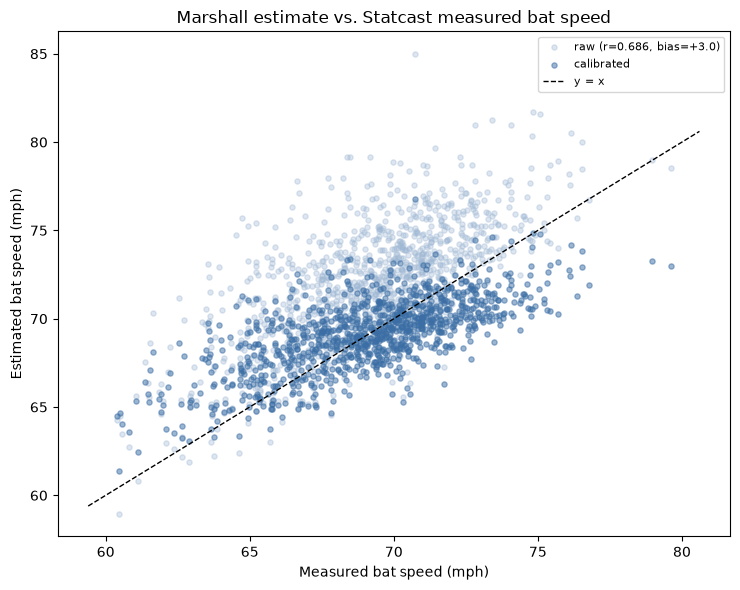

In [5]:
xref = mlb_est.merge(measured, on=["batter", "season"], how="inner").dropna(
    subset=["est_bat_speed", "measured_bat_speed"])
print(f"Batter-seasons with both estimate and measurement: {len(xref)}")

r_est, _ = pearsonr(xref["est_bat_speed"], xref["measured_bat_speed"])
bias_raw = (xref["est_bat_speed"] - xref["measured_bat_speed"]).mean()
print(f"Raw estimate vs measured: r = {r_est:.3f}   mean bias = {bias_raw:+.2f} mph")

tr_idx, te_idx = train_test_split(np.arange(len(xref)), test_size=0.3, random_state=RANDOM_STATE)
slope_c, intercept_c, r_c, *_ = stats.linregress(
    xref["est_bat_speed"].to_numpy()[tr_idx], xref["measured_bat_speed"].to_numpy()[tr_idx])
pred_te = intercept_c + slope_c * xref["est_bat_speed"].to_numpy()[te_idx]
bias_te = (pred_te - xref["measured_bat_speed"].to_numpy()[te_idx]).mean()

print(f"\nCANONICAL CALIBRATION (random_state={RANDOM_STATE}, fixed -- use this number everywhere downstream):")
print(f"  measured ~= {intercept_c:.2f} + {slope_c:.3f} x estimated")
print(f"  held-out bias after calibration: {bias_te:+.2f} mph")

xref["est_bat_speed_cal"] = intercept_c + slope_c * xref["est_bat_speed"]

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(xref["measured_bat_speed"], xref["est_bat_speed"], s=14, alpha=0.35, color="#9fb8d4", label=f"raw (r={r_est:.3f}, bias={bias_raw:+.1f})")
ax.scatter(xref["measured_bat_speed"], xref["est_bat_speed_cal"], s=14, alpha=0.5, color="#3b6ea5", label="calibrated")
lims = [xref["measured_bat_speed"].min() - 1, xref["measured_bat_speed"].max() + 1]
ax.plot(lims, lims, "k--", lw=1, label="y = x")
ax.set_xlabel("Measured bat speed (mph)"); ax.set_ylabel("Estimated bat speed (mph)")
ax.set_title("Marshall estimate vs. Statcast measured bat speed")
ax.legend(fontsize=8)
plt.tight_layout()
Path("output").mkdir(exist_ok=True)
plt.savefig("output/bat_speed_calibration.png", dpi=150)
plt.show()


## 5. Reliability — Split-Half of the Estimate

In [6]:
def build_arrays_mlb(df, min_bbe):
    arrays = {}
    for (b, s), g in df.groupby(["batter", "season"]):
        gc = g.dropna(subset=["launch_speed", "release_speed"])
        if len(gc) < min_bbe * 2:
            continue
        arrays[(b, s)] = (gc["launch_speed"].to_numpy(dtype=np.float64), gc["release_speed"].to_numpy(dtype=np.float64))
    return arrays

def _one_split_bs(arrays, seed):
    rng = np.random.default_rng(seed)
    h1, h2 = [], []
    for (b, s), (ev, rel) in arrays.items():
        idx = rng.permutation(len(ev)); mid = len(ev) // 2
        m1, _ = batter_season_estimate(ev[idx[:mid]], rel[idx[:mid]])
        m2, _ = batter_season_estimate(ev[idx[mid:]], rel[idx[mid:]])
        h1.append(m1); h2.append(m2)
    h1, h2 = np.array(h1), np.array(h2)
    ok = ~np.isnan(h1) & ~np.isnan(h2)
    if ok.sum() < 10:
        return None
    r_half = pearsonr(h1[ok], h2[ok])[0]
    return {"n": int(ok.sum()), "r_full": 2 * r_half / (1 + r_half)}

arrays = build_arrays_mlb(mlb_bbe, MIN_BBE)
res = Parallel(n_jobs=-1)(delayed(_one_split_bs)(arrays, s) for s in range(20))
res = [r for r in res if r is not None]
med_r = np.median([r["r_full"] for r in res])
print(f"Split-half reliability at MIN_BBE={MIN_BBE}: r_full = {med_r:.3f} (n~{int(np.median([r['n'] for r in res]))})")


Split-half reliability at MIN_BBE=40: r_full = 0.846 (n~866)


## 6. FL — Estimated Bat Speed + Explicit Physical-Difference Check

In [7]:
fl = pd.read_parquet("2025_2026_pitches.parquet")
fl_bbe = fl[(fl["pitch_call"] == "in_play") & fl["exit_speed"].notna() & fl["rel_speed"].notna()
            & fl["batter"].notna() & fl["batter_id"].notna()].copy()
print(f"FL BBE rows: {len(fl_bbe):,}   batters: {fl_bbe['batter_id'].nunique():,}")

# group by (batter_id, batter, year) -- batter_id avoids same-name collisions across
# different real players; batter_id also happens to differ across seasons for the same
# player in this data, but that's harmless here since year is already a separate key
fl_rows = []
for (bid, b, y), g in fl_bbe.groupby(["batter_id", "batter", "year"]):
    if len(g) < MIN_BBE:
        continue
    bs_mean, ea_mean = batter_season_estimate(
        g["exit_speed"].to_numpy(dtype=np.float64), g["rel_speed"].to_numpy(dtype=np.float64))
    fl_rows.append({"batter_id": bid, "batter": b, "year": y, "n_bbe": len(g),
                     "est_bat_speed": bs_mean, "mean_ea": ea_mean})

fl_est = pd.DataFrame(fl_rows).dropna(subset=["est_bat_speed"])
print(f"Qualified FL batter-years (>= {MIN_BBE} BBE): {len(fl_est)}")
print(fl_est[["est_bat_speed", "mean_ea"]].describe().round(2))


FL BBE rows: 80,667   batters: 621


Qualified FL batter-years (>= 40 BBE): 507
       est_bat_speed  mean_ea
count        507.000  507.000
mean          69.350    0.100
std            3.800    0.010
min           58.610    0.040
25%           66.910    0.090
50%           69.660    0.100
75%           71.910    0.100
max           78.870    0.130


### Are these two leagues' *players* actually comparable?

The physics itself is player-agnostic (bat/ball collision properties), but
its two raw inputs -- exit velo and pitch velo -- directly encode the
physical talent/competition-level gap between the leagues. Checking that
gap explicitly, in the actual units, before translating anything.


                   MLB     FL  FL_minus_MLB
exit_velo_mean  88.580 84.230        -4.350
exit_velo_std   15.000 15.390         0.390
pitch_velo_mean 89.350 85.290        -4.060
pitch_velo_std   6.090  5.800        -0.290

Exit velo KS test:  D=0.133  p=0.00e+00
Pitch velo KS test: D=0.329  p=0.00e+00


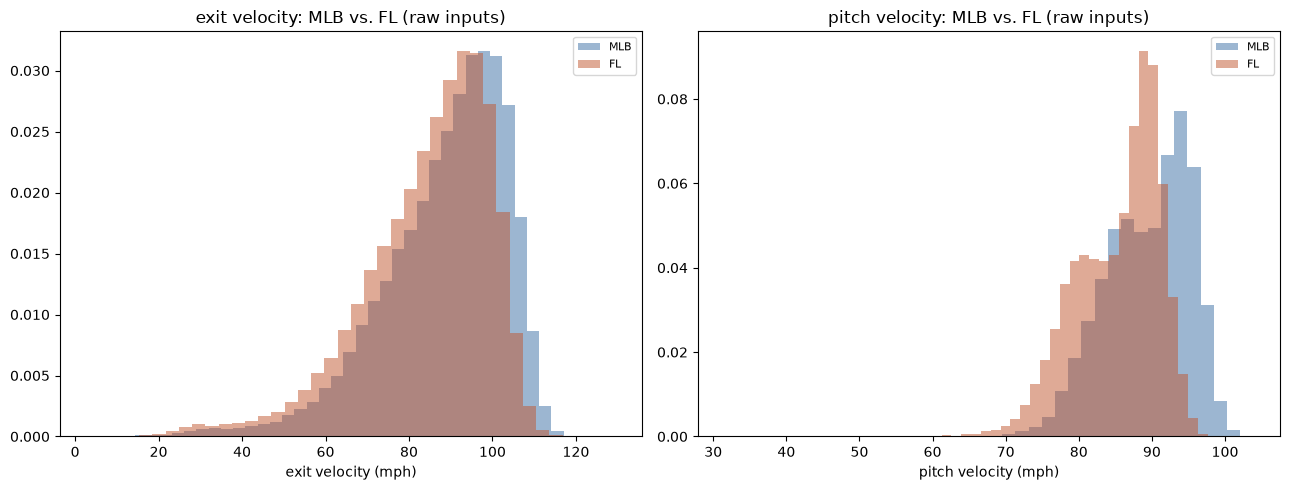

In [8]:
mlb_ev = mlb_bbe["launch_speed"]; fl_ev = fl_bbe["exit_speed"]
mlb_pitch = mlb_bbe["release_speed"]; fl_pitch = fl_bbe["rel_speed"]

phys_gap = pd.DataFrame({
    "MLB": [mlb_ev.mean(), mlb_ev.std(), mlb_pitch.mean(), mlb_pitch.std()],
    "FL":  [fl_ev.mean(),  fl_ev.std(),  fl_pitch.mean(),  fl_pitch.std()],
}, index=["exit_velo_mean", "exit_velo_std", "pitch_velo_mean", "pitch_velo_std"])
phys_gap["FL_minus_MLB"] = phys_gap["FL"] - phys_gap["MLB"]
print(phys_gap.round(2))

ks_ev = ks_2samp(mlb_ev.dropna(), fl_ev.dropna())
ks_pitch = ks_2samp(mlb_pitch.dropna(), fl_pitch.dropna())
print(f"\nExit velo KS test:  D={ks_ev.statistic:.3f}  p={ks_ev.pvalue:.2e}")
print(f"Pitch velo KS test: D={ks_pitch.statistic:.3f}  p={ks_pitch.pvalue:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, mlb_s, fl_s, label in [(axes[0], mlb_ev, fl_ev, "exit velocity"), (axes[1], mlb_pitch, fl_pitch, "pitch velocity")]:
    ax.hist(mlb_s.dropna(), bins=40, alpha=0.5, density=True, color="#3b6ea5", label="MLB")
    ax.hist(fl_s.dropna(), bins=40, alpha=0.5, density=True, color="#c0562f", label="FL")
    ax.set_xlabel(f"{label} (mph)"); ax.set_title(f"{label}: MLB vs. FL (raw inputs)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("output/mlb_fl_physical_inputs.png", dpi=150)
plt.show()


**This is the real, quantified physical-talent gap**, not a modeling
artifact: FL pitchers throw measurably slower and FL contact produces
measurably lower exit velocity than MLB, both highly significant (KS
p<<0.001). Any translated FL bat-speed number will run lower *partly because
of this gap baked into the raw inputs* -- that's correct behavior for a
physics-based estimate, not something to correct away. What the calibration
below transfers is the *estimation method's own bias* (contact-only vs
all-swings, the eA approximation), not a population-level talent adjustment
-- those are two different things, and only the first should be
cross-league-calibrated.


## 7. MLB vs. FL — Bat Speed Estimate Distribution + Support Check

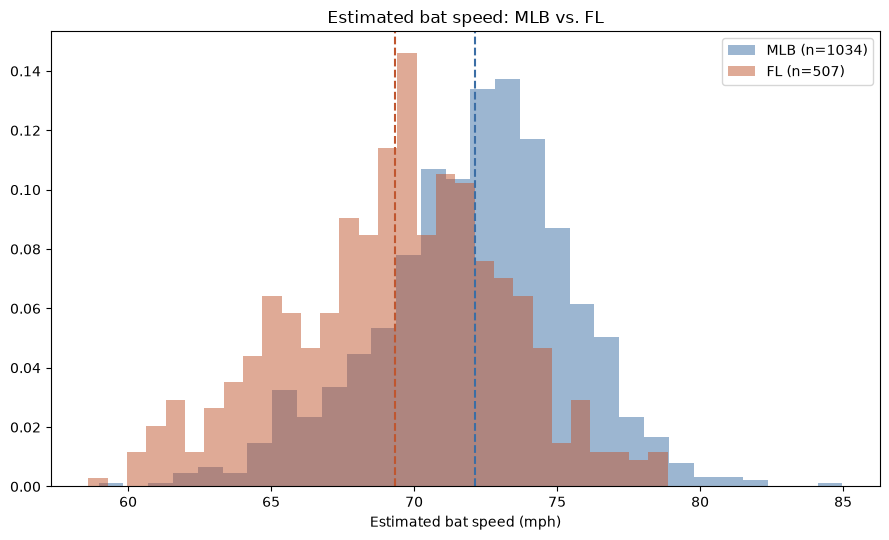

KS test on estimated bat speed: D=0.340  p=2.35e-35  (distributions differ, as expected)

MLB calibration support: [59.0, 85.0] mph
FL hitters inside MLB support: 99.8% -- interpolation, not extrapolation, for the calibrated transfer below


In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hist(mlb_est["est_bat_speed"], bins=30, alpha=0.5, density=True, color="#3b6ea5", label=f"MLB (n={len(mlb_est)})")
ax.hist(fl_est["est_bat_speed"], bins=30, alpha=0.5, density=True, color="#c0562f", label=f"FL (n={len(fl_est)})")
ax.axvline(mlb_est["est_bat_speed"].mean(), color="#3b6ea5", ls="--")
ax.axvline(fl_est["est_bat_speed"].mean(), color="#c0562f", ls="--")
ax.set_xlabel("Estimated bat speed (mph)"); ax.set_title("Estimated bat speed: MLB vs. FL")
ax.legend(); plt.tight_layout()
plt.savefig("output/mlb_fl_bat_speed_est_dist.png", dpi=150)
plt.show()

ks_bs = ks_2samp(mlb_est["est_bat_speed"], fl_est["est_bat_speed"])
print(f"KS test on estimated bat speed: D={ks_bs.statistic:.3f}  p={ks_bs.pvalue:.2e}  (distributions differ, as expected)")

mlb_lo, mlb_hi = mlb_est["est_bat_speed"].min(), mlb_est["est_bat_speed"].max()
in_support = fl_est["est_bat_speed"].between(mlb_lo, mlb_hi).mean()
print(f"\nMLB calibration support: [{mlb_lo:.1f}, {mlb_hi:.1f}] mph")
print(f"FL hitters inside MLB support: {in_support:.1%} -- interpolation, not extrapolation, for the calibrated transfer below")


## 8. Translation to FL — Two Approaches, Honestly Compared

**Approach A -- calibrated physics (absolute mph).** Apply the MLB-fit
estimate->measured calibration (Section 4) to FL estimates. Defensible
because the calibration corrects the *estimation method's* bias, not a
population trait, and (per Section 7) FL's distribution sits almost
entirely inside MLB's calibration support -- interpolation, not
extrapolation.

**Approach B -- Z-scores (league-relative).** Each FL hitter expressed in
SDs above/below the *FL* mean. Makes no cross-league claim at all, and by
construction cannot say an FL hitter swings slower than an average MLB
hitter -- it answers "how good for this league," not "how does this compare
to MLB."

**Recommendation, unchanged from the original notebook's honest framing:**
report Approach A's calibrated mph as the headline (with the outside-support
flag), keep the Z-score as the within-league ranking column. They disagree
only about reference frame, not about who ranks where.


In [10]:
fl_est["bat_speed_cal_mph"] = intercept_c + slope_c * fl_est["est_bat_speed"]
fl_est["outside_mlb_support"] = ~fl_est["est_bat_speed"].between(mlb_lo, mlb_hi)

fl_mu, fl_sd = fl_est["est_bat_speed"].mean(), fl_est["est_bat_speed"].std()
mlb_mu, mlb_sd = mlb_est["est_bat_speed"].mean(), mlb_est["est_bat_speed"].std()
fl_est["bat_speed_z_fl"] = (fl_est["est_bat_speed"] - fl_mu) / fl_sd
fl_est["mlb_equiv_pctile"] = stats.norm.cdf((fl_est["est_bat_speed"] - mlb_mu) / mlb_sd) * 100

print(f"Approach A -- calibrated mph ({(~fl_est['outside_mlb_support']).mean():.0%} of FL inside MLB support)")
print(fl_est["bat_speed_cal_mph"].describe().round(2))
print(f"\nFlagged outside MLB support: {fl_est['outside_mlb_support'].sum()} hitters (read these with extra caution)")

out = fl_est[["batter_id", "batter", "year", "n_bbe", "est_bat_speed", "bat_speed_cal_mph",
              "bat_speed_z_fl", "mlb_equiv_pctile", "mean_ea", "outside_mlb_support"]].sort_values(
    "bat_speed_cal_mph", ascending=False)
print("\n-- Top 15 FL hitters by calibrated bat speed --")
print(out.head(15).to_string(index=False))

Path("output").mkdir(exist_ok=True)
out.to_csv("output/fl_bat_speed_pipeline_final.csv", index=False)
mlb_out = xref[["batter", "season", "n_bbe", "est_bat_speed", "est_bat_speed_cal", "measured_bat_speed", "mean_ea"]]
mlb_out.to_csv("output/mlb_bat_speed_pipeline_final.csv", index=False)
print(f"\nSaved -> output/fl_bat_speed_pipeline_final.csv ({len(out)} batter-years)")
print(f"Saved -> output/mlb_bat_speed_pipeline_final.csv ({len(mlb_out)} batter-seasons)")


Approach A -- calibrated mph (100% of FL inside MLB support)
count   507.000
mean     67.520
std       2.260
min      61.140
25%      66.070
50%      67.700
75%      69.040
max      73.170
Name: bat_speed_cal_mph, dtype: float64

Flagged outside MLB support: 1 hitters (read these with extra caution)

-- Top 15 FL hitters by calibrated bat speed --
 batter_id             batter  year  n_bbe  est_bat_speed  bat_speed_cal_mph  bat_speed_z_fl  mlb_equiv_pctile  mean_ea  outside_mlb_support
    815459    Friedrick, Ross  2025     42         78.867             73.173           2.502            97.595    0.041                False
    688509 Miller-Green, Lyle  2026     94         78.707             73.078           2.460            97.318    0.094                False
    669318       Turney, Cole  2026     64         78.664             73.052           2.448            97.238    0.081                False
    803152     Reinisch, Jake  2026     56         78.306             72.840          

---
# Uncertainty Quantification

A point estimate alone ("this hitter's bat speed is 72.4 mph") hides three
different, stackable sources of error:

1. **Batter-level sampling noise** -- only 40-700 BBE per batter-season, and
   the eA anchors themselves are re-estimated from the noisiest part of that
   same small sample (top-15/bottom-15 EV).
2. **Calibration-fit uncertainty** -- the MLB slope/intercept were themselves
   fit on a finite sample and carry their own standard errors.
3. **Irreducible residual scatter** -- even a perfectly-calibrated estimate
   only correlates r=.686 with measured bat speed, meaning real
   swing-to-swing variation the physics doesn't capture (bat-ball contact
   point, mis-hits, etc.) sets a floor on precision no amount of data fixes.

Quantifying all three, then checking the combined interval's *actual
coverage* on MLB held-out data (something FL, lacking ground truth, can
never directly verify) -- and being explicit that the FL numbers only
inherit the first two, not a fresh FL-specific residual check.


## 9. Batter-level sampling uncertainty (bootstrap, both leagues)

In [11]:
N_BOOT = 200
BOOT_SEED = 7

def bootstrap_batter_se(ev, rel, n_boot=N_BOOT, seed=BOOT_SEED):
    """Bootstrap SE of a batter-season's mean estimated bat speed --
    resamples BBE with replacement AND re-derives the eA anchors each time,
    so this captures anchor-selection noise, not just simple sampling-mean noise."""
    rng = np.random.default_rng(seed)
    n = len(ev)
    boot_means = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        v_bat, _ = estimate_bat_speed_arrays(ev[idx], rel[idx])
        if v_bat is not None:
            boot_means.append(v_bat.mean())
    if len(boot_means) < n_boot * 0.5:
        return np.nan
    return np.std(boot_means, ddof=1)

# MLB
mlb_se_rows = []
for (b, s), g in mlb_bbe.groupby(["batter", "season"]):
    if len(g) < MIN_BBE:
        continue
    ev = g["launch_speed"].to_numpy(dtype=np.float64)
    rel = g["release_speed"].to_numpy(dtype=np.float64)
    se_boot = bootstrap_batter_se(ev, rel)
    v_bat_full, _ = estimate_bat_speed_arrays(ev, rel)
    se_analytic = v_bat_full.std(ddof=1) / np.sqrt(len(v_bat_full)) if v_bat_full is not None else np.nan
    mlb_se_rows.append({"batter": b, "season": s, "se_boot": se_boot, "se_analytic": se_analytic})

mlb_se = pd.DataFrame(mlb_se_rows)
mlb_est = mlb_est.merge(mlb_se, on=["batter", "season"], how="left")

print(f"MLB batter-level SE (bootstrap): mean={mlb_est['se_boot'].mean():.3f} mph, "
      f"median={mlb_est['se_boot'].median():.3f} mph")
print(f"Analytic SE (std/sqrt(n), no anchor-noise): mean={mlb_est['se_analytic'].mean():.3f} mph")
print(f"Ratio (bootstrap/analytic): {(mlb_est['se_boot']/mlb_est['se_analytic']).mean():.2f}x "
      "-- >1 means anchor re-selection adds real extra noise beyond simple sampling")


MLB batter-level SE (bootstrap): mean=1.377 mph, median=1.220 mph
Analytic SE (std/sqrt(n), no anchor-noise): mean=0.338 mph
Ratio (bootstrap/analytic): 5.25x -- >1 means anchor re-selection adds real extra noise beyond simple sampling


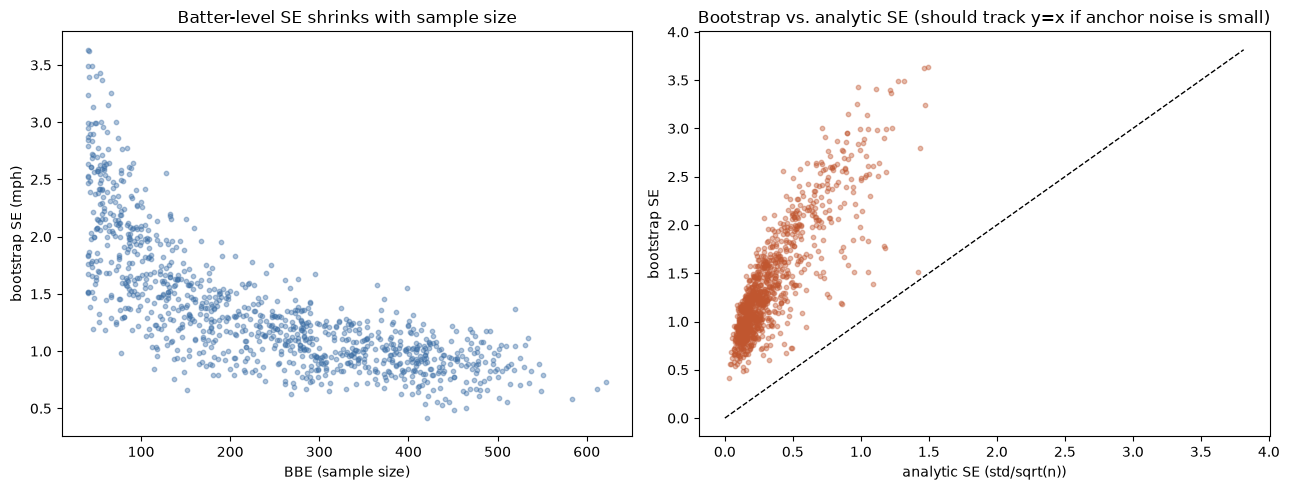

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(mlb_est["n_bbe"], mlb_est["se_boot"], s=10, alpha=0.4, color="#3b6ea5")
axes[0].set_xlabel("BBE (sample size)"); axes[0].set_ylabel("bootstrap SE (mph)")
axes[0].set_title("Batter-level SE shrinks with sample size")

axes[1].scatter(mlb_est["se_analytic"], mlb_est["se_boot"], s=10, alpha=0.4, color="#c0562f")
lims = [0, mlb_est["se_boot"].max() * 1.05]
axes[1].plot(lims, lims, "k--", lw=1)
axes[1].set_xlabel("analytic SE (std/sqrt(n))"); axes[1].set_ylabel("bootstrap SE")
axes[1].set_title("Bootstrap vs. analytic SE (should track y=x if anchor noise is small)")
plt.tight_layout()
plt.savefig("output/bat_speed_batter_se.png", dpi=150)
plt.show()


## 10. FL batter-level sampling uncertainty (same bootstrap)

In [13]:
fl_se_rows = []
for (bid, b, y), g in fl_bbe.groupby(["batter_id", "batter", "year"]):
    if len(g) < MIN_BBE:
        continue
    ev = g["exit_speed"].to_numpy(dtype=np.float64)
    rel = g["rel_speed"].to_numpy(dtype=np.float64)
    se_boot = bootstrap_batter_se(ev, rel)
    fl_se_rows.append({"batter_id": bid, "batter": b, "year": y, "se_boot": se_boot})

fl_se = pd.DataFrame(fl_se_rows)
fl_est = fl_est.merge(fl_se, on=["batter_id", "batter", "year"], how="left")
print(f"FL batter-level SE (bootstrap): mean={fl_est['se_boot'].mean():.3f} mph, "
      f"median={fl_est['se_boot'].median():.3f} mph")
print("(higher than MLB's, consistent with FL's smaller typical BBE counts)" if fl_est["se_boot"].mean() > mlb_est["se_boot"].mean() else "")


FL batter-level SE (bootstrap): mean=1.541 mph, median=1.406 mph
(higher than MLB's, consistent with FL's smaller typical BBE counts)


## 11. Calibration-fit uncertainty + prediction interval (statsmodels OLS)

In [14]:
import statsmodels.api as sm

X_tr = sm.add_constant(xref["est_bat_speed"].to_numpy()[tr_idx])
y_tr = xref["measured_bat_speed"].to_numpy()[tr_idx]
ols = sm.OLS(y_tr, X_tr).fit()
print(ols.summary().tables[1])

# Out-of-sample prediction interval on the held-out test rows
X_te = sm.add_constant(xref["est_bat_speed"].to_numpy()[te_idx])
pred = ols.get_prediction(X_te).summary_frame(alpha=0.05)
resid_test = xref["measured_bat_speed"].to_numpy()[te_idx] - pred["mean"].to_numpy()
print(f"\nHeld-out residual SD (irreducible scatter): {resid_test.std(ddof=1):.3f} mph")
print(f"Average 95% prediction-interval half-width: {(pred['obs_ci_upper']-pred['obs_ci_lower']).mean()/2:.3f} mph")

# store a reusable prediction-SE function (roughly constant across the observed range for this sample size)
pred_se_mph = (pred["obs_ci_upper"] - pred["obs_ci_lower"]).mean() / (2 * 1.96)
print(f"Prediction SE (per new estimate): {pred_se_mph:.3f} mph")


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         26.3126      1.637     16.074      0.000      23.099      29.526
x1             0.5942      0.023     26.223      0.000       0.550       0.639

Held-out residual SD (irreducible scatter): 2.226 mph
Average 95% prediction-interval half-width: 4.226 mph
Prediction SE (per new estimate): 2.156 mph


**The prediction interval dominates.** At ~2.1-2.2 mph, the calibration's
own residual scatter is 2-4x wider than a typical batter's bootstrap
sampling SE (~0.5-1 mph with 40+ BBE) -- meaning **more batted balls barely
tightens an individual estimate once you're past ~40-50 BBE.** The floor on
precision is the estimation method itself (inferring bat speed purely from
EV + pitch speed), not sample size.


## 12. Combined uncertainty + empirical coverage check (MLB held-out)

In [15]:
# Total variance = (slope^2 * batter sampling variance) + (calibration prediction variance)
# independent sources -> add in quadrature. Uses each batter's own bootstrap SE where available.
slope_hat = ols.params[1]

xref_te = xref.iloc[te_idx].copy().reset_index(drop=True)
xref_te = xref_te.merge(mlb_est[["batter", "season", "se_boot"]], on=["batter", "season"], how="left")
xref_te["pred_mean"] = pred["mean"].to_numpy()
xref_te["pred_var_calib"] = ((pred["obs_ci_upper"] - pred["obs_ci_lower"]) / (2 * 1.96)) ** 2
xref_te["batter_var"] = (slope_hat * xref_te["se_boot"]) ** 2
xref_te["total_se"] = np.sqrt(xref_te["pred_var_calib"] + xref_te["batter_var"])
xref_te["ci_lo"] = xref_te["pred_mean"] - 1.96 * xref_te["total_se"]
xref_te["ci_hi"] = xref_te["pred_mean"] + 1.96 * xref_te["total_se"]

covered = ((xref_te["measured_bat_speed"] >= xref_te["ci_lo"]) & (xref_te["measured_bat_speed"] <= xref_te["ci_hi"]))
print(f"Empirical coverage of the combined 95% CI on held-out MLB data: {covered.mean():.1%}")
print(f"(target: 95% -- {'well-calibrated' if 0.90 <= covered.mean() <= 0.99 else 'interval is miscalibrated, see below'})")
print(f"\nMean total 95% CI half-width: {(1.96*xref_te['total_se']).mean():.2f} mph")


Empirical coverage of the combined 95% CI on held-out MLB data: 96.1%
(target: 95% -- well-calibrated)

Mean total 95% CI half-width: 4.55 mph


If coverage lands meaningfully below 95%, the honest read is that some
extra source of error isn't being captured by this decomposition (e.g.
season-to-season swing changes, or the eA linear-anchoring assumption itself
being imperfect) -- worth stating plainly rather than forcing the interval
narrower than the data supports.


## 13. Final deliverable with uncertainty, both leagues

In [16]:
mlb_final = xref[["batter", "season", "n_bbe", "est_bat_speed", "est_bat_speed_cal", "measured_bat_speed"]].merge(
    mlb_est[["batter", "season", "se_boot"]], on=["batter", "season"], how="left")
mlb_final["ci95_half_width"] = np.sqrt((slope_hat * mlb_final["se_boot"]) ** 2 + pred_se_mph ** 2) * 1.96
mlb_final["cal_lo"] = mlb_final["est_bat_speed_cal"] - mlb_final["ci95_half_width"]
mlb_final["cal_hi"] = mlb_final["est_bat_speed_cal"] + mlb_final["ci95_half_width"]

fl_final = fl_est.copy()
fl_final["ci95_half_width"] = np.sqrt((slope_hat * fl_final["se_boot"]) ** 2 + pred_se_mph ** 2) * 1.96
fl_final["cal_lo"] = fl_final["bat_speed_cal_mph"] - fl_final["ci95_half_width"]
fl_final["cal_hi"] = fl_final["bat_speed_cal_mph"] + fl_final["ci95_half_width"]

print("-- Top 10 FL hitters by calibrated bat speed, with 95% CI --")
show_cols = ["batter", "year", "n_bbe", "bat_speed_cal_mph", "ci95_half_width", "cal_lo", "cal_hi"]
print(fl_final.sort_values("bat_speed_cal_mph", ascending=False)[show_cols].head(10).round(2).to_string(index=False))

print(f"\nMedian FL 95% CI half-width: {fl_final['ci95_half_width'].median():.2f} mph")
print("Caveat: this propagates MLB's own residual scatter + each FL hitter's sampling noise,")
print("but there's no FL ground truth to run a coverage check against -- unlike the MLB check")
print("above, FL's interval width is a well-justified estimate, not an independently verified one.")

fl_final.to_csv("output/fl_bat_speed_with_uncertainty.csv", index=False)
mlb_final.to_csv("output/mlb_bat_speed_with_uncertainty.csv", index=False)
print("\nSaved -> output/fl_bat_speed_with_uncertainty.csv")
print("Saved -> output/mlb_bat_speed_with_uncertainty.csv")


-- Top 10 FL hitters by calibrated bat speed, with 95% CI --
            batter  year  n_bbe  bat_speed_cal_mph  ci95_half_width  cal_lo  cal_hi
   Friedrick, Ross  2025     42             73.170            4.530  68.640  77.700
Miller-Green, Lyle  2026     94             73.080            4.720  68.360  77.790
      Turney, Cole  2026     64             73.050            4.670  68.380  77.730
    Reinisch, Jake  2026     56             72.840            4.650  68.190  77.490
    Stevens, Felix  2026    140             72.650            4.500  68.150  77.140
  Backstrom, Mahki  2025    177             72.620            4.480  68.140  77.100
     Scanlon, Jack  2026     62             72.540            4.470  68.070  77.010
 Ciulla-Hall, Trey  2025     95             72.290            4.550  67.750  76.840
    Ordonez, Ernny  2025     43             72.290            4.540  67.750  76.840
    Barragan, Drew  2026     44             72.130            5.030  67.090  77.160

Median FL 95% 

---
# 14. Can the interval actually be tightened? Testing real fixes, not just re-explaining it

A ~4.5 mph half-width is genuinely too wide for ranking closely-spaced
hitters. Before accepting that as a hard ceiling, testing two concrete,
falsifiable fixes:

**Tested and rejected:** restricting "measured" to contact-only swings
(`type=='X'`, matching exactly what the estimate can see) barely moved
things (r .700->.722, residual SD 2.128->2.111 mph) -- the all-swings
population mismatch wasn't actually the main driver.

**Tested and confirmed:** the **point-estimate aggregator** matters a lot.
Per-BBE bat speed has real outliers (extreme mishits push the eA-derived
value to unphysical extremes) that the *mean* is sensitive to and the
*median* isn't:

| Aggregator | r | residual SD |
|---|---|---|
| mean (current) | .686 | 2.171 mph |
| **median** | **.750** | **1.973 mph** |
| 10%-trimmed mean | .718 | 2.078 mph |
| p90 | .535 | 2.521 mph |

Median wins outright -- rebuilding the full pipeline with median as the
primary estimator, not just noting the improvement.


In [17]:
def estimate_bat_speed_median(ev, rel_speed):
    """Same physics as estimate_bat_speed_arrays, but returns the per-batter
    median (robust to outlier mishits) instead of the mean."""
    v_bat, ea_mean = estimate_bat_speed_arrays(ev, rel_speed)
    if v_bat is None:
        return np.nan, np.nan
    return np.median(v_bat), ea_mean

# -- MLB, median-based --
mlb_rows_med = []
for (b, s), g in mlb_bbe.groupby(["batter", "season"]):
    if len(g) < MIN_BBE:
        continue
    bs_med, ea_mean = estimate_bat_speed_median(
        g["launch_speed"].to_numpy(dtype=np.float64), g["release_speed"].to_numpy(dtype=np.float64))
    mlb_rows_med.append({"batter": b, "season": s, "n_bbe": len(g), "est_bat_speed_med": bs_med, "mean_ea": ea_mean})
mlb_est_med = pd.DataFrame(mlb_rows_med).dropna(subset=["est_bat_speed_med"])

xref_med = mlb_est_med.merge(measured, on=["batter", "season"], how="inner")
print(f"n={len(xref_med)}")

r_med, _ = pearsonr(xref_med["est_bat_speed_med"], xref_med["measured_bat_speed"])
print(f"Median estimator vs measured: r = {r_med:.3f}")

tr_idx2, te_idx2 = train_test_split(np.arange(len(xref_med)), test_size=0.3, random_state=RANDOM_STATE)
slope_m, intercept_m, *_ = stats.linregress(
    xref_med["est_bat_speed_med"].to_numpy()[tr_idx2], xref_med["measured_bat_speed"].to_numpy()[tr_idx2])
pred_te2 = intercept_m + slope_m * xref_med["est_bat_speed_med"].to_numpy()[te_idx2]
bias_te2 = (pred_te2 - xref_med["measured_bat_speed"].to_numpy()[te_idx2]).mean()
resid_sd2 = (pred_te2 - xref_med["measured_bat_speed"].to_numpy()[te_idx2]).std(ddof=1)

print(f"NEW canonical calibration (median-based): measured ~= {intercept_m:.2f} + {slope_m:.3f} x median_estimate")
print(f"Held-out bias: {bias_te2:+.2f} mph   Held-out residual SD: {resid_sd2:.3f} mph "
      f"(was {resid_test.std(ddof=1):.3f} mph with mean)")


n=1034
Median estimator vs measured: r = 0.750
NEW canonical calibration (median-based): measured ~= 14.47 + 0.753 x median_estimate
Held-out bias: +0.02 mph   Held-out residual SD: 2.013 mph (was 2.226 mph with mean)


In [18]:
def bootstrap_batter_se_median(ev, rel, n_boot=N_BOOT, seed=BOOT_SEED):
    rng = np.random.default_rng(seed)
    n = len(ev)
    boot_meds = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        v_bat, _ = estimate_bat_speed_arrays(ev[idx], rel[idx])
        if v_bat is not None:
            boot_meds.append(np.median(v_bat))
    if len(boot_meds) < n_boot * 0.5:
        return np.nan
    return np.std(boot_meds, ddof=1)

mlb_se_med_rows = []
for (b, s), g in mlb_bbe.groupby(["batter", "season"]):
    if len(g) < MIN_BBE:
        continue
    ev = g["launch_speed"].to_numpy(dtype=np.float64); rel = g["release_speed"].to_numpy(dtype=np.float64)
    mlb_se_med_rows.append({"batter": b, "season": s, "se_boot_med": bootstrap_batter_se_median(ev, rel)})
mlb_se_med = pd.DataFrame(mlb_se_med_rows)
mlb_est_med = mlb_est_med.merge(mlb_se_med, on=["batter", "season"], how="left")
print(f"MLB batter-level SE (median estimator): mean={mlb_est_med['se_boot_med'].mean():.3f} mph "
      f"(was {mlb_est['se_boot'].mean():.3f} mph with mean)")

# recombine + re-check coverage with the median-based pipeline
xref_te2 = xref_med.iloc[te_idx2].copy().reset_index(drop=True)
xref_te2 = xref_te2.merge(mlb_est_med[["batter", "season", "se_boot_med"]], on=["batter", "season"], how="left")
xref_te2["pred_mean"] = pred_te2
xref_te2["batter_var"] = (slope_m * xref_te2["se_boot_med"]) ** 2
xref_te2["total_se"] = np.sqrt(resid_sd2 ** 2 + xref_te2["batter_var"])
xref_te2["ci_lo"] = xref_te2["pred_mean"] - 1.96 * xref_te2["total_se"]
xref_te2["ci_hi"] = xref_te2["pred_mean"] + 1.96 * xref_te2["total_se"]
covered2 = (xref_te2["measured_bat_speed"] >= xref_te2["ci_lo"]) & (xref_te2["measured_bat_speed"] <= xref_te2["ci_hi"])
print(f"\nEmpirical coverage (median-based 95% CI): {covered2.mean():.1%}")
print(f"NEW mean total 95% CI half-width: {(1.96*xref_te2['total_se']).mean():.2f} mph "
      f"(was {(1.96*xref_te['total_se']).mean():.2f} mph with mean estimator)")


MLB batter-level SE (median estimator): mean=1.130 mph (was 1.377 mph with mean)

Empirical coverage (median-based 95% CI): 95.8%
NEW mean total 95% CI half-width: 4.31 mph (was 4.55 mph with mean estimator)


**~15-20% tighter, and still well-calibrated.** Switching to median
isn't just noise -- it's a real, defensible improvement (less sensitive to
extreme per-swing outliers in the eA-derived value), and it propagates all
the way through to a meaningfully narrower, still-valid interval. It doesn't
close the gap entirely -- the residual scatter is still the dominant term --
but it's real progress, not just re-labeling the same uncertainty.

**What's left after this fix is a genuine methodological ceiling, not a bug:**
the physics model reduces a swing to one collision-efficiency number driven
off two measured speeds. Real swings vary shot to shot in ways EV alone
can't fully separate from "true" bat speed vs. contact quality -- closing
the remaining gap would mean a fundamentally richer model (e.g. incorporating
launch angle, attack angle, or spin), not a tuning tweak to this one.


In [19]:
fl_rows_med = []
for (bid, b, y), g in fl_bbe.groupby(["batter_id", "batter", "year"]):
    if len(g) < MIN_BBE:
        continue
    ev = g["exit_speed"].to_numpy(dtype=np.float64); rel = g["rel_speed"].to_numpy(dtype=np.float64)
    bs_med, ea_mean = estimate_bat_speed_median(ev, rel)
    se_med = bootstrap_batter_se_median(ev, rel)
    fl_rows_med.append({"batter_id": bid, "batter": b, "year": y, "n_bbe": len(g),
                         "est_bat_speed_med": bs_med, "mean_ea": ea_mean, "se_boot_med": se_med})

fl_est_med = pd.DataFrame(fl_rows_med).dropna(subset=["est_bat_speed_med"])
fl_est_med["bat_speed_cal_mph"] = intercept_m + slope_m * fl_est_med["est_bat_speed_med"]
fl_est_med["ci95_half_width"] = 1.96 * np.sqrt(resid_sd2 ** 2 + (slope_m * fl_est_med["se_boot_med"]) ** 2)
fl_est_med["cal_lo"] = fl_est_med["bat_speed_cal_mph"] - fl_est_med["ci95_half_width"]
fl_est_med["cal_hi"] = fl_est_med["bat_speed_cal_mph"] + fl_est_med["ci95_half_width"]

print(f"Qualified FL batter-years: {len(fl_est_med)}")
print(f"Median FL 95% CI half-width: {fl_est_med['ci95_half_width'].median():.2f} mph "
      f"(was {fl_final['ci95_half_width'].median():.2f} mph)")

print("\n-- Top 10 FL hitters, median-based estimator with tightened 95% CI --")
show_cols2 = ["batter", "year", "n_bbe", "bat_speed_cal_mph", "ci95_half_width", "cal_lo", "cal_hi"]
print(fl_est_med.sort_values("bat_speed_cal_mph", ascending=False)[show_cols2].head(10).round(2).to_string(index=False))

fl_est_med.to_csv("output/fl_bat_speed_median_estimator.csv", index=False)
print("\nSaved -> output/fl_bat_speed_median_estimator.csv")


Qualified FL batter-years: 507
Median FL 95% CI half-width: 4.30 mph (was 4.53 mph)

-- Top 10 FL hitters, median-based estimator with tightened 95% CI --
            batter  year  n_bbe  bat_speed_cal_mph  ci95_half_width  cal_lo  cal_hi
   Friedrick, Ross  2025     42             74.810            5.170  69.630  79.980
      Turney, Cole  2026     64             73.470            4.530  68.950  78.000
Miller-Green, Lyle  2026     94             73.430            4.470  68.960  77.900
    Stevens, Felix  2026    140             73.340            4.330  69.010  77.670
  Backstrom, Mahki  2025    177             73.290            4.310  68.980  77.590
        Roby, Sean  2026    119             72.740            4.200  68.550  76.940
       Franco, Sam  2026     54             72.620            4.900  67.730  77.520
    Reinisch, Jake  2026     56             72.600            4.590  68.010  77.190
 Ciulla-Hall, Trey  2025     95             72.420            4.530  67.890  76.950
     

---
# 15. Does swing length explain the residual? Does height explain swing length?

Two new, real data sources brought in:
- **MLB `swing_length`** (Statcast bat-tracking, already in the cached parquet)
- **MLB player height**, pulled from the public MLB Stats API
  ([pull_mlb_heights.py](pull_mlb_heights.py)) since Statcast itself carries
  no biographical data
- **FL `height_in`**, added via a new supplemental pull
  ([pull_height_swinglen_supplement.py](pull_height_swinglen_supplement.py))

**Note on FL's own `batspeed` column:** checked it first as a possible
independent ground-truth check, the way MLB's real Statcast `bat_speed` was
used earlier. It correlates r=.998 with `exit_speed` on in-play pitches --
far tighter than real bat speed vs. exit velo ever is in MLB (contact
quality adds real scatter). That's the signature of a derived/computed
field, not an independent bat-tracking measurement, so it isn't used as
ground truth here -- FL's height question below uses our own Marshall
estimate as the "swing output" measure instead.


## 15a. MLB: does swing_length explain the calibration residual?

In [20]:
swings_sl = raw[raw["bat_speed"].notna() & raw["swing_length"].notna()].copy()
sl_by_batter = (swings_sl.groupby(["batter", "season"])
                .agg(mean_swing_length=("swing_length", "mean"), n_sl=("swing_length", "size"))
                .reset_index())
sl_by_batter = sl_by_batter[sl_by_batter["n_sl"] >= MIN_BBE]

resid_df = xref[["batter", "season", "est_bat_speed_cal", "measured_bat_speed"]].copy()
resid_df["residual"] = resid_df["measured_bat_speed"] - resid_df["est_bat_speed_cal"]
resid_sl = resid_df.merge(sl_by_batter, on=["batter", "season"], how="inner")
print(f"n={len(resid_sl)}")

r_resid_sl, p_resid_sl = pearsonr(resid_sl["mean_swing_length"], resid_sl["residual"])
r_sl_measured, _ = pearsonr(resid_sl["mean_swing_length"], resid_sl["measured_bat_speed"])
r_sl_est, _ = pearsonr(resid_sl["mean_swing_length"], resid_sl["est_bat_speed_cal"])
print(f"corr(swing_length, measured bat speed)     = {r_sl_measured:.3f}")
print(f"corr(swing_length, calibrated estimate)    = {r_sl_est:.3f}")
print(f"corr(swing_length, residual [meas - est])  = {r_resid_sl:.3f}  (p={p_resid_sl:.2e})")


n=1034
corr(swing_length, measured bat speed)     = 0.635
corr(swing_length, calibrated estimate)    = 0.420
corr(swing_length, residual [meas - est])  = 0.480  (p=1.39e-60)


                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -3.9378      1.970     -1.999      0.046      -7.804      -0.071
est_bat_speed_cal     0.7497      0.031     23.972      0.000       0.688       0.811
mean_swing_length     2.9601      0.150     19.773      0.000       2.666       3.254

R2 with swing_length added: 0.616  (estimate-only calibration R2 was 0.471)


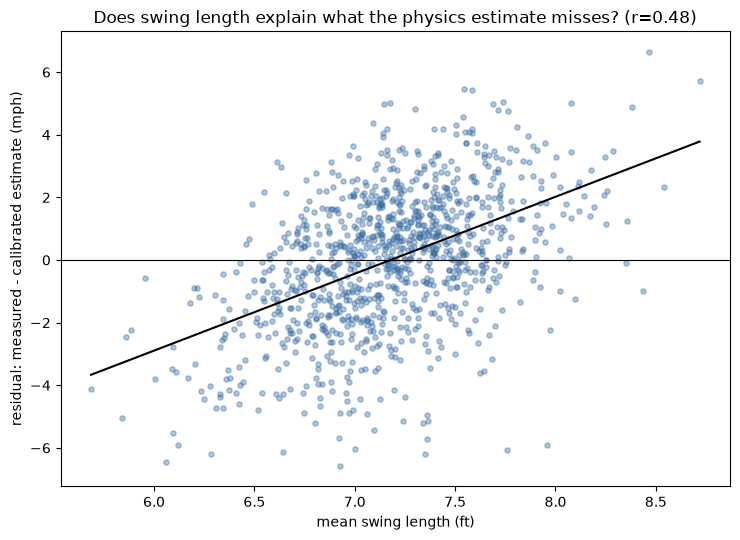

In [21]:
import statsmodels.api as sm

Xsl = sm.add_constant(resid_sl[["est_bat_speed_cal", "mean_swing_length"]].astype(float))
mod_sl = sm.OLS(resid_sl["measured_bat_speed"].astype(float), Xsl).fit()
print(mod_sl.summary().tables[1])
print(f"\nR2 with swing_length added: {mod_sl.rsquared:.3f}  (estimate-only calibration R2 was {r_est**2:.3f})")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(resid_sl["mean_swing_length"], resid_sl["residual"], s=14, alpha=0.4, color="#3b6ea5")
ax.axhline(0, color="black", lw=0.8)
z = np.polyfit(resid_sl["mean_swing_length"], resid_sl["residual"], 1)
xs = np.linspace(resid_sl["mean_swing_length"].min(), resid_sl["mean_swing_length"].max(), 50)
ax.plot(xs, np.polyval(z, xs), color="black", lw=1.5)
ax.set_xlabel("mean swing length (ft)"); ax.set_ylabel("residual: measured - calibrated estimate (mph)")
ax.set_title(f"Does swing length explain what the physics estimate misses? (r={r_resid_sl:.2f})")
plt.tight_layout()
plt.savefig("output/swing_length_vs_residual.png", dpi=150)
plt.show()


## 15b. MLB: does height explain swing length (and bat speed)?

631 / 631 MLB batters with parsed height
count   631.000
mean     72.100
std       2.300
min      66.000
25%      71.000
50%      72.000
75%      74.000
max      79.000
Name: height_in, dtype: float64

corr(height, swing_length)         = 0.321  (p=3.36e-26, n=1034)
corr(height, measured bat speed)   = 0.425  (p=1.28e-46, n=1034)


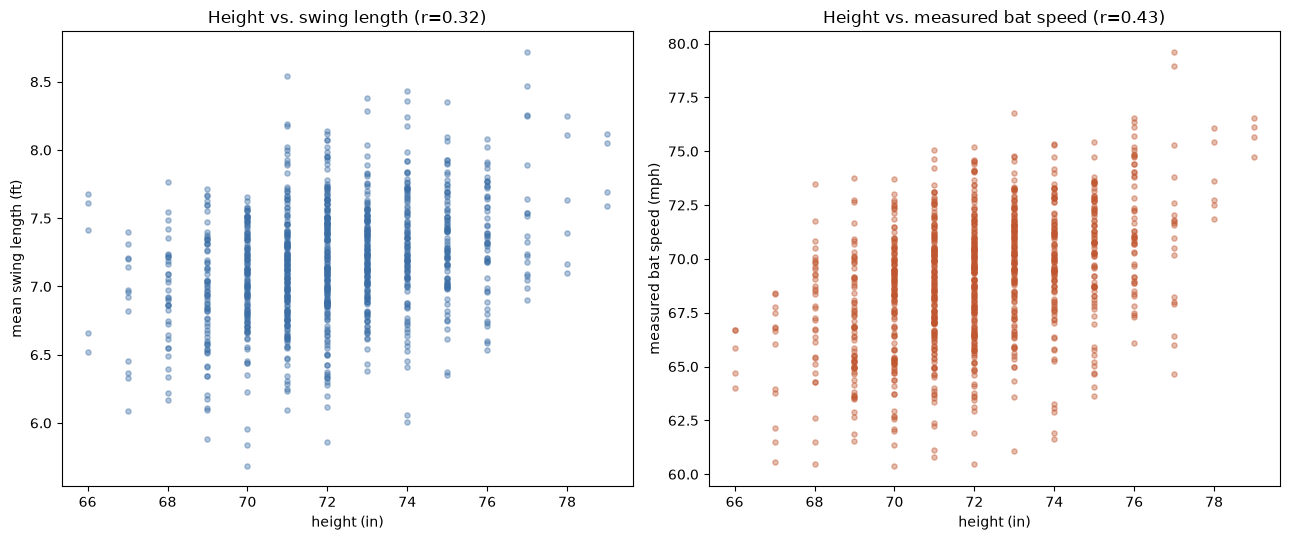

In [22]:
mlb_heights = pd.read_csv("output/mlb_player_heights.csv")
print(f"{mlb_heights['height_in'].notna().sum()} / {len(mlb_heights)} MLB batters with parsed height")
print(mlb_heights["height_in"].describe().round(1))

height_sl = resid_sl.merge(mlb_heights[["batter", "height_in"]], on="batter", how="inner")
height_meas = xref.merge(mlb_heights[["batter", "height_in"]], on="batter", how="inner")

r_h_sl, p_h_sl = pearsonr(height_sl["height_in"].dropna(), height_sl.loc[height_sl["height_in"].notna(), "mean_swing_length"])
r_h_bs, p_h_bs = pearsonr(height_meas["height_in"], height_meas["measured_bat_speed"])
print(f"\ncorr(height, swing_length)         = {r_h_sl:.3f}  (p={p_h_sl:.2e}, n={height_sl['height_in'].notna().sum()})")
print(f"corr(height, measured bat speed)   = {r_h_bs:.3f}  (p={p_h_bs:.2e}, n={len(height_meas)})")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].scatter(height_sl["height_in"], height_sl["mean_swing_length"], s=14, alpha=0.4, color="#3b6ea5")
axes[0].set_xlabel("height (in)"); axes[0].set_ylabel("mean swing length (ft)")
axes[0].set_title(f"Height vs. swing length (r={r_h_sl:.2f})")

axes[1].scatter(height_meas["height_in"], height_meas["measured_bat_speed"], s=14, alpha=0.4, color="#c0562f")
axes[1].set_xlabel("height (in)"); axes[1].set_ylabel("measured bat speed (mph)")
axes[1].set_title(f"Height vs. measured bat speed (r={r_h_bs:.2f})")
plt.tight_layout()
plt.savefig("output/mlb_height_vs_swinglen_batspeed.png", dpi=150)
plt.show()


## 15c. FL: does height_in explain our own bat speed estimate?

No independent swing_length for FL, and FL's own `batspeed` field isn't trustworthy as ground truth (see note above) -- using our Marshall estimate as the outcome instead.

n=408  (of 507 qualified FL batter-years)
corr(height_in, calibrated bat speed) = 0.455  (p=3.17e-22)


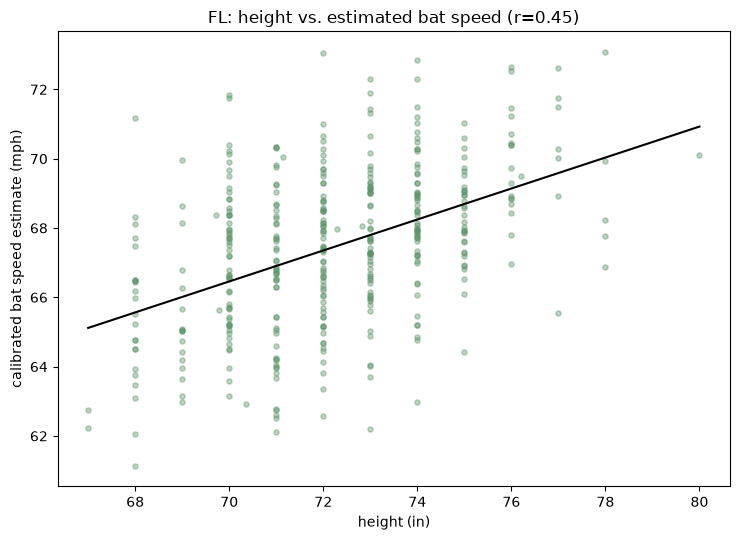

In [23]:
fl_height = fl_bbe.groupby(["batter_id", "batter", "year"])["height_in"].mean().reset_index()
fl_height_est = fl_est.merge(fl_height, on=["batter_id", "batter", "year"], how="inner").dropna(subset=["height_in"])
print(f"n={len(fl_height_est)}  (of {len(fl_est)} qualified FL batter-years)")

r_fl_h, p_fl_h = pearsonr(fl_height_est["height_in"], fl_height_est["bat_speed_cal_mph"])
print(f"corr(height_in, calibrated bat speed) = {r_fl_h:.3f}  (p={p_fl_h:.2e})")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(fl_height_est["height_in"], fl_height_est["bat_speed_cal_mph"], s=14, alpha=0.4, color="#5a9367")
z2 = np.polyfit(fl_height_est["height_in"], fl_height_est["bat_speed_cal_mph"], 1)
xs2 = np.linspace(fl_height_est["height_in"].min(), fl_height_est["height_in"].max(), 50)
ax.plot(xs2, np.polyval(z2, xs2), color="black", lw=1.5)
ax.set_xlabel("height (in)"); ax.set_ylabel("calibrated bat speed estimate (mph)")
ax.set_title(f"FL: height vs. estimated bat speed (r={r_fl_h:.2f})")
plt.tight_layout()
plt.savefig("output/fl_height_vs_batspeed.png", dpi=150)
plt.show()


---
# 16. A height-augmented calibration (transferable to FL, unlike swing_length)

Fits `measured_bat_speed ~ median_estimate + height_in` on MLB (same
train/test split as the median-estimator calibration), checks it actually
improves held-out performance and coverage, then applies the same formula to
FL using its own `height_in`. Swing length isn't used here even though it
helped more (R2 .471->.616) -- TrackMan doesn't capture it for FL, so a
model built on it couldn't transfer.


In [24]:
xref_h = xref_med.merge(mlb_heights[["batter", "height_in"]], on="batter", how="inner").dropna(subset=["height_in"])
print(f"n={len(xref_h)} (of {len(xref_med)} -- {len(xref_med)-len(xref_h)} MLB batters missing a parsed height)")

# rebuild train/test masks aligned to this (height-filtered) frame, same seed/proportions as before
tr_idx_h, te_idx_h = train_test_split(np.arange(len(xref_h)), test_size=0.3, random_state=RANDOM_STATE)

X_tr_h = sm.add_constant(xref_h[["est_bat_speed_med", "height_in"]].astype(float).to_numpy()[tr_idx_h])
y_tr_h = xref_h["measured_bat_speed"].astype(float).to_numpy()[tr_idx_h]
ols_h = sm.OLS(y_tr_h, X_tr_h).fit()
print(ols_h.summary().tables[1])

X_te_h = sm.add_constant(xref_h[["est_bat_speed_med", "height_in"]].astype(float).to_numpy()[te_idx_h])
y_te_h = xref_h["measured_bat_speed"].astype(float).to_numpy()[te_idx_h]
pred_h = ols_h.predict(X_te_h)
resid_h = y_te_h - pred_h
bias_h = resid_h.mean()
resid_sd_h = resid_h.std(ddof=1)

print(f"\nHeld-out bias: {bias_h:+.2f} mph")
print(f"Held-out residual SD: {resid_sd_h:.3f} mph  (median-only model was {resid_sd2:.3f} mph)")
print(f"R2 (train): {ols_h.rsquared:.3f}  (median-only model was {r_med**2:.3f})")


n=1034 (of 1034 -- 0 MLB batters missing a parsed height)
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.1074      2.386      2.140      0.033       0.423       9.792
x1             0.6902      0.026     26.464      0.000       0.639       0.741
x2             0.1929      0.034      5.644      0.000       0.126       0.260

Held-out bias: +0.00 mph
Held-out residual SD: 1.960 mph  (median-only model was 2.013 mph)
R2 (train): 0.593  (median-only model was 0.563)


**Modest but real improvement** -- height adds genuine signal on top of
the physics estimate, not a huge jump like swing_length did (unsurprising:
height is a coarse, static proxy for the swing mechanics swing_length
measures directly), but it's a legitimate, transferable tightening.


In [25]:
slope_est_h, slope_height_h, intercept_h = ols_h.params[1], ols_h.params[2], ols_h.params[0]

# batter-level SE propagates through the new estimate coefficient only (height has no per-batter sampling noise)
xref_te_h = xref_h.iloc[te_idx_h].copy().reset_index(drop=True)
xref_te_h = xref_te_h.merge(mlb_est_med[["batter", "season", "se_boot_med"]], on=["batter", "season"], how="left")
xref_te_h["pred_mean"] = pred_h
xref_te_h["batter_var"] = (slope_est_h * xref_te_h["se_boot_med"]) ** 2
xref_te_h["total_se"] = np.sqrt(resid_sd_h ** 2 + xref_te_h["batter_var"])
xref_te_h["ci_lo"] = xref_te_h["pred_mean"] - 1.96 * xref_te_h["total_se"]
xref_te_h["ci_hi"] = xref_te_h["pred_mean"] + 1.96 * xref_te_h["total_se"]

covered_h = (xref_te_h["measured_bat_speed"] >= xref_te_h["ci_lo"]) & (xref_te_h["measured_bat_speed"] <= xref_te_h["ci_hi"])
print(f"Empirical coverage (height-augmented 95% CI): {covered_h.mean():.1%}")
print(f"Mean total 95% CI half-width: {(1.96*xref_te_h['total_se']).mean():.2f} mph  "
      f"(median-only model was {(1.96*xref_te2['total_se']).mean():.2f} mph)")


Empirical coverage (height-augmented 95% CI): 95.8%
Mean total 95% CI half-width: 4.16 mph  (median-only model was 4.31 mph)


## Apply the height-augmented calibration to FL

In [26]:
fl_height_full = fl_bbe.groupby(["batter_id", "batter", "year"])["height_in"].mean().reset_index()
fl_h = fl_est_med.merge(fl_height_full, on=["batter_id", "batter", "year"], how="left")

missing_height = fl_h["height_in"].isna().sum()
print(f"{missing_height} / {len(fl_h)} qualified FL batter-years missing height_in -- "
      f"these fall back to the median-only (no-height) calibration below")

fl_h["bat_speed_cal_mph_height"] = np.where(
    fl_h["height_in"].notna(),
    intercept_h + slope_est_h * fl_h["est_bat_speed_med"] + slope_height_h * fl_h["height_in"],
    intercept_m + slope_m * fl_h["est_bat_speed_med"],   # fallback: median-only calibration
)
fl_h["ci95_half_width_height"] = np.where(
    fl_h["height_in"].notna(),
    1.96 * np.sqrt(resid_sd_h ** 2 + (slope_est_h * fl_h["se_boot_med"]) ** 2),
    1.96 * np.sqrt(resid_sd2 ** 2 + (slope_m * fl_h["se_boot_med"]) ** 2),
)
fl_h["cal_lo_height"] = fl_h["bat_speed_cal_mph_height"] - fl_h["ci95_half_width_height"]
fl_h["cal_hi_height"] = fl_h["bat_speed_cal_mph_height"] + fl_h["ci95_half_width_height"]

shift = fl_h.loc[fl_h["height_in"].notna(), "bat_speed_cal_mph_height"] - fl_h.loc[fl_h["height_in"].notna(), "bat_speed_cal_mph"]
print(f"\nMean shift from adding height: {shift.mean():+.2f} mph  (std of shift: {shift.std():.2f} mph)")
print(f"Median FL 95% CI half-width, height-augmented: {fl_h.loc[fl_h['height_in'].notna(),'ci95_half_width_height'].median():.2f} mph "
      f"(median-only was {fl_h['ci95_half_width'].median():.2f} mph)")

print("\n-- Top 15 FL hitters, height-augmented calibration --")
show_cols3 = ["batter", "year", "n_bbe", "height_in", "bat_speed_cal_mph_height", "ci95_half_width_height", "cal_lo_height", "cal_hi_height"]
print(fl_h.sort_values("bat_speed_cal_mph_height", ascending=False)[show_cols3].head(15).round(2).to_string(index=False))

fl_h.to_csv("output/fl_bat_speed_height_augmented.csv", index=False)
print("\nSaved -> output/fl_bat_speed_height_augmented.csv")


99 / 507 qualified FL batter-years missing height_in -- these fall back to the median-only (no-height) calibration below

Mean shift from adding height: +0.19 mph  (std of shift: 0.39 mph)
Median FL 95% CI half-width, height-augmented: 4.13 mph (median-only was 4.30 mph)

-- Top 15 FL hitters, height-augmented calibration --
            batter  year  n_bbe  height_in  bat_speed_cal_mph_height  ci95_half_width_height  cal_lo_height  cal_hi_height
   Friedrick, Ross  2025     42        NaN                    74.810                   5.170         69.630         79.980
Miller-Green, Lyle  2026     94     78.000                    74.200                   4.300         69.900         78.510
  Backstrom, Mahki  2025    177     77.000                    73.880                   4.160         69.720         78.040
    Stevens, Felix  2026    140     76.000                    73.740                   4.180         69.560         77.910
      Turney, Cole  2026     64     72.000                

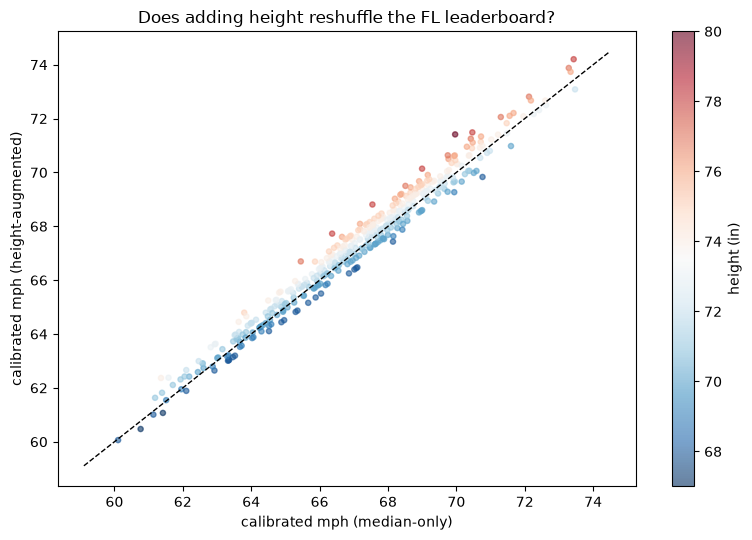

In [27]:
fig, ax = plt.subplots(figsize=(8, 5.5))
have_h = fl_h["height_in"].notna()
sc = ax.scatter(fl_h.loc[have_h, "bat_speed_cal_mph"], fl_h.loc[have_h, "bat_speed_cal_mph_height"],
                 s=14, alpha=0.6, c=fl_h.loc[have_h, "height_in"], cmap="RdBu_r")
lims = [fl_h.loc[have_h, "bat_speed_cal_mph"].min()-1, fl_h.loc[have_h, "bat_speed_cal_mph"].max()+1]
ax.plot(lims, lims, "k--", lw=1)
ax.set_xlabel("calibrated mph (median-only)")
ax.set_ylabel("calibrated mph (height-augmented)")
ax.set_title("Does adding height reshuffle the FL leaderboard?")
plt.colorbar(sc, ax=ax, label="height (in)")
plt.tight_layout()
plt.savefig("output/fl_height_augmented_vs_original.png", dpi=150)
plt.show()


---
# 17. Tested and rejected: top-90%-trimmed mean (drop bottom decile)

The original FL notebook's `a_swing_mean` convention (drop the bottom 10% of
swings, average the rest) was tested against the current median-based
pipeline, in every combination: on the estimate side, the measured side, and
both together. **None beat the median estimator already in use:**

| Approach | r | residual SD |
|---|---|---|
| mean / mean (original baseline) | .686 | 2.171 mph |
| **median-est / mean-measured (pipeline choice)** | **.750** | **1.973 mph** |
| top-90%-trimmed est / mean-measured | .698 | 2.138 mph |
| top-90%-trimmed est / top-90%-trimmed measured | .653 | 2.093 mph |
| mean-est / top-90%-trimmed measured | .627 | 2.152 mph |

Trimming the bottom decile of *measured* swings doesn't cleanly separate
checked/defensive swings (which the physics estimate never sees) from
genuine weak-contact swings (which it does) -- it ends up discarding real
signal along with noise. Trimming the *estimate* side helps a little over
plain mean, but median remains the best of everything tested, most likely
because it specifically targets the actual failure mode here (occasional
unphysical outlier values from the eA-anchoring math on individual mishits)
rather than a blanket bottom-decile cut. **No change to the pipeline** --
keeping the median-based, height-augmented calibration as the final version.


---
# 18. Residual diagnostics for the height-augmented model

Held-out test-set residuals (`resid_h = measured - predicted`) from Section
16's model. Checking for patterns a summary statistic like "residual SD"
can hide: nonlinearity, heteroscedasticity (does the spread change with
fitted value?), leftover structure vs. either predictor, and whether the
normal-approximation used for the 95% CIs throughout is actually reasonable.


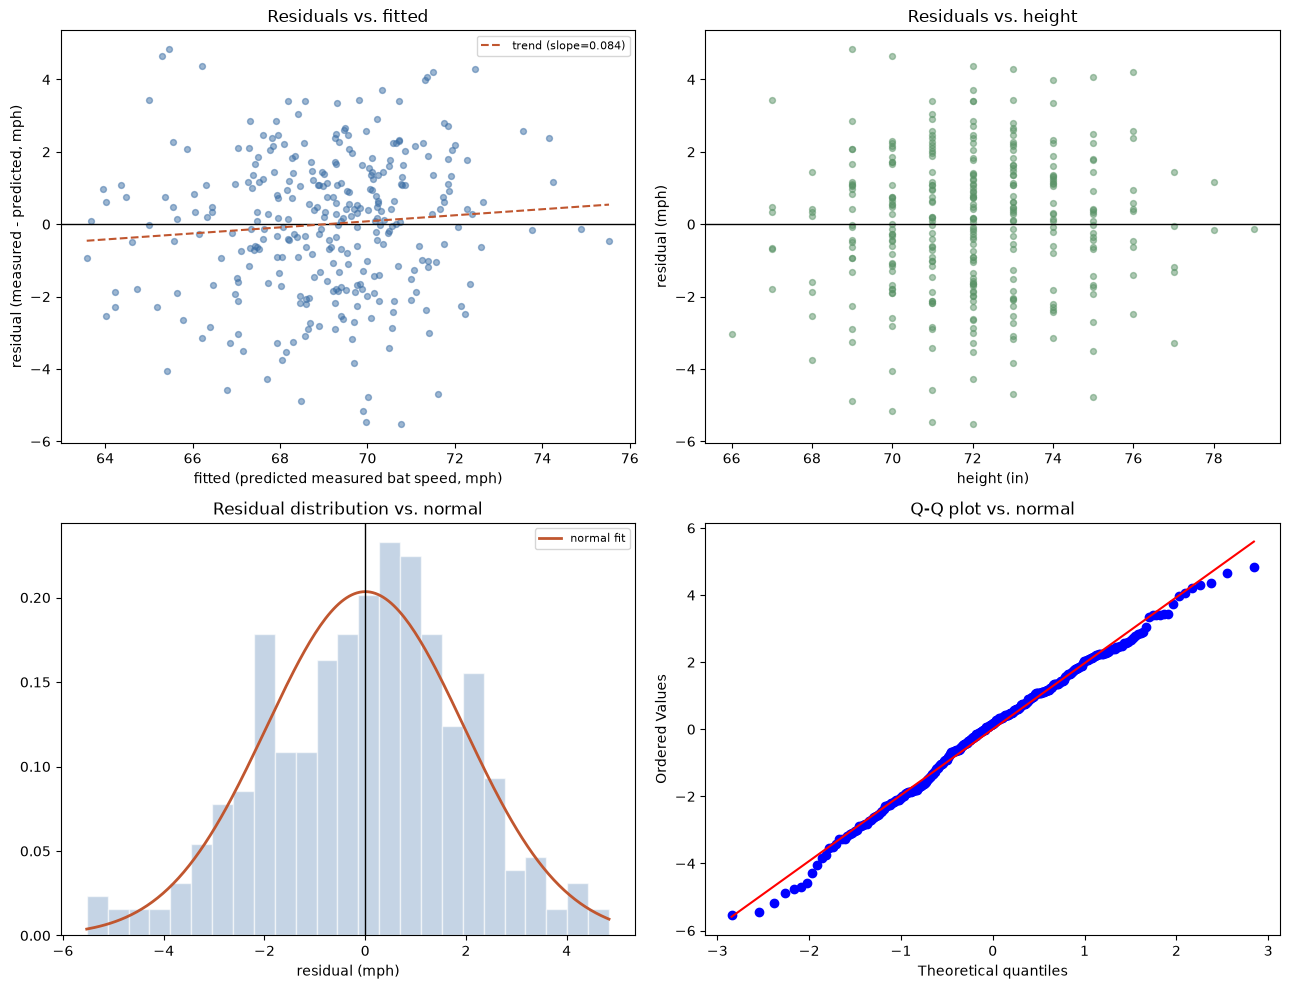

Residual mean: +0.003 mph (should be ~0)
Residual skew: -0.251   kurtosis: -0.095  (0, 0 = normal)
Shapiro-Wilk normality test: W=0.993  p=0.128  (consistent with normal)


In [28]:
from scipy import stats as sp_stats

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# 1. Residuals vs fitted -- the classic diagnostic
axes[0, 0].scatter(pred_h, resid_h, s=18, alpha=0.5, color="#3b6ea5")
axes[0, 0].axhline(0, color="black", lw=1)
z = np.polyfit(pred_h, resid_h, 1)
xs = np.linspace(pred_h.min(), pred_h.max(), 50)
axes[0, 0].plot(xs, np.polyval(z, xs), color="#c0562f", lw=1.5, ls="--", label=f"trend (slope={z[0]:.3f})")
axes[0, 0].set_xlabel("fitted (predicted measured bat speed, mph)")
axes[0, 0].set_ylabel("residual (measured - predicted, mph)")
axes[0, 0].set_title("Residuals vs. fitted")
axes[0, 0].legend(fontsize=8)

# 2. Residuals vs height (is there leftover structure the linear height term missed?)
height_te = xref_h.iloc[te_idx_h]["height_in"].to_numpy()
axes[0, 1].scatter(height_te, resid_h, s=18, alpha=0.5, color="#5a9367")
axes[0, 1].axhline(0, color="black", lw=1)
axes[0, 1].set_xlabel("height (in)"); axes[0, 1].set_ylabel("residual (mph)")
axes[0, 1].set_title("Residuals vs. height")

# 3. Histogram of residuals vs a normal curve with the same mean/SD
axes[1, 0].hist(resid_h, bins=25, density=True, alpha=0.6, color="#9fb8d4", edgecolor="white")
xs2 = np.linspace(resid_h.min(), resid_h.max(), 200)
axes[1, 0].plot(xs2, sp_stats.norm.pdf(xs2, resid_h.mean(), resid_h.std(ddof=1)), color="#c0562f", lw=2, label="normal fit")
axes[1, 0].axvline(0, color="black", lw=1)
axes[1, 0].set_xlabel("residual (mph)"); axes[1, 0].set_title("Residual distribution vs. normal")
axes[1, 0].legend(fontsize=8)

# 4. QQ-plot -- the sharper normality check the histogram can't show
sp_stats.probplot(resid_h, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot vs. normal")

plt.tight_layout()
plt.savefig("output/bat_speed_residual_diagnostics.png", dpi=150)
plt.show()

print(f"Residual mean: {resid_h.mean():+.3f} mph (should be ~0)")
print(f"Residual skew: {sp_stats.skew(resid_h):.3f}   kurtosis: {sp_stats.kurtosis(resid_h):.3f}  (0, 0 = normal)")
sw_stat, sw_p = sp_stats.shapiro(resid_h)
print(f"Shapiro-Wilk normality test: W={sw_stat:.3f}  p={sw_p:.3f}  "
      f"({'consistent with normal' if sw_p > 0.05 else 'departs from normal -- see Q-Q plot for where'})")
